# Sentiment analysis in context

**ANSARI JAFEERA JAMIL AHMED | UIN: 231A022 | Roll number: 03**

NLP application study: compare VADER and TextBlob on the same 36 inputs, identify linguistic failures, and propose adaptation for Hindi.

This executed notebook records actual local inference. The examples and reference labels are project-authored with AI assistance, not a published benchmark or independently annotated corpus.

## Method

Both tools use their distributed English lexicons. Preserve original text, punctuation, case and script. The original comparison uses the packages' distributed lexicons and fixed thresholds, without translation. Positive is score >= 0.05; negative is score <= -0.05; otherwise neutral. The symmetric TextBlob threshold is a project choice. Scores and subjectivity are not confidence probabilities.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image, Markdown
from sentiment_lab.engine import analyze
from sentiment_lab.evaluation import ROOT, load_dataset, evaluate, summary

rows = load_dataset()
results = evaluate(rows)
report = summary(results)
pd.Series(sorted({r['gold_label'] for r in rows}), name='Reference label vocabulary')
print(f'{len(rows)} inputs; {len(report["by_category"])} categories')
display(pd.Series([r['gold_label'] for r in rows]).value_counts().rename('Reference support'))

36 inputs; 6 categories


negative    17
positive    11
neutral      8
Name: Reference support, dtype: int64

## Try the tools with identical input

The second sentence is Hindi praise meaning 'This phone is very good.' A neutral prediction is an error against its positive reference label.

In [2]:
for text in ['I love this phone. The camera is excellent!', 'यह फोन बहुत अच्छा है।']:
    output = analyze(text)
    print(json.dumps(output, ensure_ascii=False, indent=2))

{
  "text": "I love this phone. The camera is excellent!",
  "vader_label": "positive",
  "vader_compound": 0.8478,
  "vader_positive": 0.577,
  "vader_neutral": 0.423,
  "vader_negative": 0.0,
  "textblob_label": "positive",
  "textblob_polarity": 0.75,
  "textblob_subjectivity": 0.8,
  "textblob_assessments": [
    {
      "tokens": [
        "love"
      ],
      "polarity": 0.5,
      "subjectivity": 0.6
    },
    {
      "tokens": [
        "excellent",
        "!"
      ],
      "polarity": 1.0,
      "subjectivity": 1.0
    }
  ],
  "tools_agree": true,
  "has_devanagari": false
}
{
  "text": "यह फोन बहुत अच्छा है।",
  "vader_label": "neutral",
  "vader_compound": 0.0,
  "vader_positive": 0.0,
  "vader_neutral": 1.0,
  "vader_negative": 0.0,
  "textblob_label": "neutral",
  "textblob_polarity": 0.0,
  "textblob_subjectivity": 0.0,
  "textblob_assessments": [],
  "tools_agree": true,
  "has_devanagari": true
}


## All measured predictions

Reference labels express the intended reading. See the meaning and challenge columns for annotation decisions.

In [3]:
frame = pd.DataFrame(results)
with pd.option_context('display.max_rows', 50, 'display.max_colwidth', 100):
    display(frame[['id', 'text', 'gold_label', 'vader_label', 'vader_compound', 'textblob_label', 'textblob_polarity']])

,id,text,gold_label,vader_label,vader_compound,textblob_label,textblob_polarity
0,EN01,I love this phone. The camera is excellent!,positive,positive,0.8478,positive,0.750000
1,EN02,The delivery was fast and the staff were helpful.,positive,positive,0.4215,positive,0.200000
2,EN03,This product is terrible and a waste of money.,negative,negative,-0.7096,negative,-0.600000
3,EN04,I hate the slow service and rude staff.,negative,negative,-0.7717,negative,-0.466667
4,EN05,The package arrived on Tuesday.,neutral,neutral,0.0000,neutral,0.000000
5,EN06,The phone has a 6 inch screen.,neutral,neutral,0.0000,neutral,0.000000
6,NG01,This phone is not good.,negative,negative,-0.3412,negative,-0.350000
7,NG02,The service is not bad at all.,positive,positive,0.4310,positive,0.350000
8,NG03,I am not happy with this purchase.,negative,negative,-0.4585,negative,-0.400000
9,NG04,I do not hate this movie.,positive,positive,0.4585,positive,0.400000


## Aggregate comparison

Accuracy is the fraction of labels matching the references. Macro F1 is the arithmetic mean of negative, neutral and positive F1, with undefined values set to zero. The overall scores describe this deliberately difficult, small set. An always-negative predictor scores 17/36 = 47.2%.

In [4]:
display(pd.DataFrame({tool: {'n': m['n'], 'accuracy': m['accuracy'], 'macro_f1': m['macro_f1']} for tool, m in report['overall'].items()}).T)
print('Different labels:', report['disagreements'])
display(pd.DataFrame([{ 'category': cat, 'n': values['vader']['n'], 'vader_accuracy': values['vader']['accuracy'], 'textblob_accuracy': values['textblob']['accuracy']} for cat, values in report['by_category'].items()]))

,n,accuracy,macro_f1
vader,36.0,0.500000,0.497669
textblob,36.0,0.555556,0.554865


Different labels: 4


,category,n,vader_accuracy,textblob_accuracy
0,English,6,1.000000,1.000000
1,Hindi,6,0.333333,0.333333
2,Hinglish,6,0.333333,0.333333
3,Indian English,6,0.333333,0.666667
4,Negation,6,1.000000,1.000000
5,Sarcasm,6,0.000000,0.000000


vader confusion matrix: reference rows, predicted columns


,negative,neutral,positive
negative,5,6,6
neutral,0,7,1
positive,0,5,6


textblob confusion matrix: reference rows, predicted columns


,negative,neutral,positive
negative,6,7,4
neutral,0,8,0
positive,0,5,6


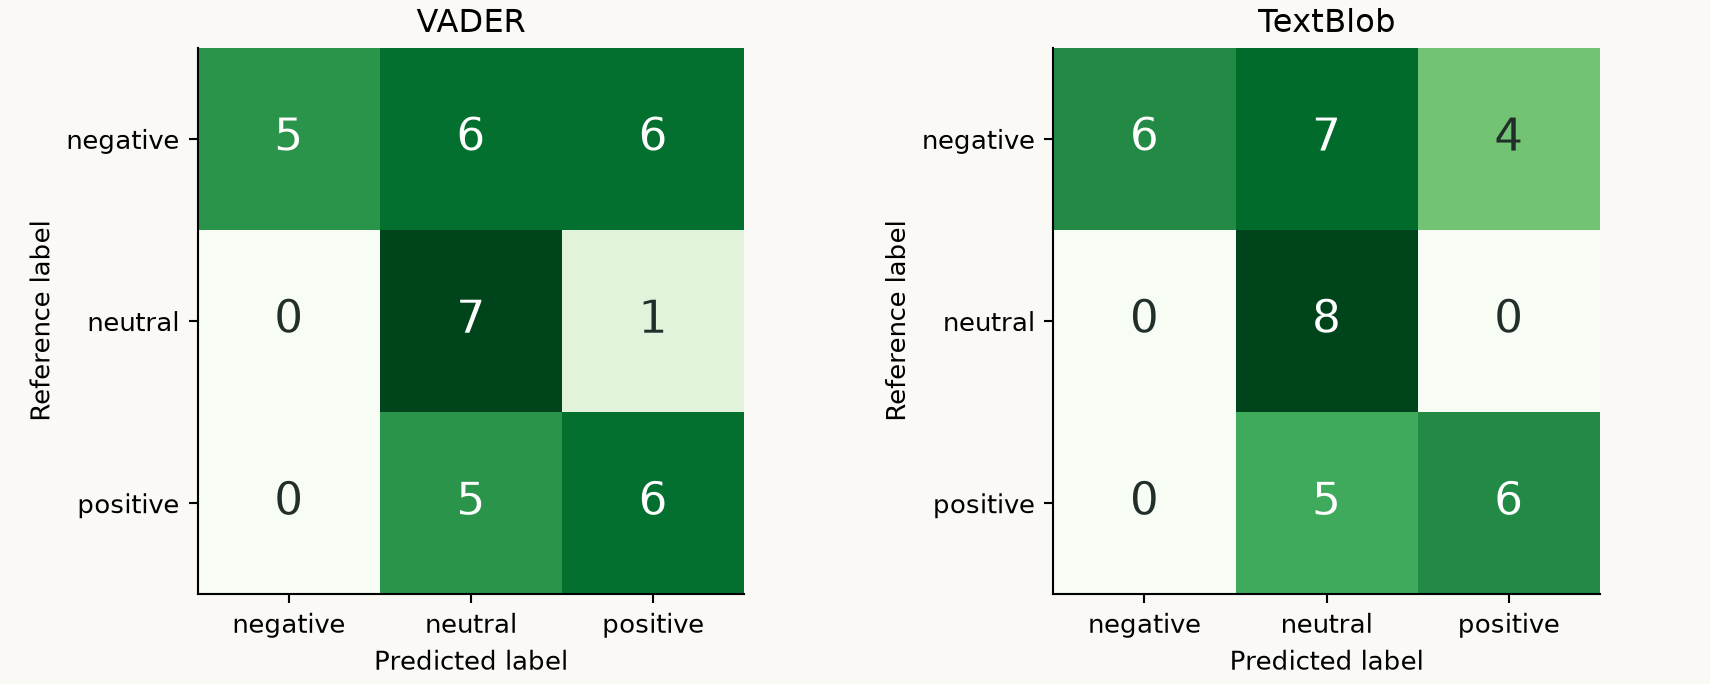

In [5]:
for tool in ['vader', 'textblob']:
    m = report['overall'][tool]
    print(tool, 'confusion matrix: reference rows, predicted columns')
    display(pd.DataFrame(m['confusion_matrix'], index=m['labels'], columns=m['labels']))
display(Image(filename=str(ROOT / 'reports/figures/confusion_matrices.png')))

## Errors and cultural context

SA03 has a floating-point threshold effect: TextBlob returns 0.04999999999999999, which is below 0.05 even though it displays as 0.0500. Labels use full precision. Either label misses the negative reference.

Both tools succeed on straightforward English and these negation cases. Both miss all sarcastic complaints. 'Paisa vasool' and 'third class' expose regional expression gaps. Every Hindi and Hinglish input returns neutral, including praise and criticism. Correct neutral predictions for factual Hindi do not prove language comprehension. VADER's positive output for the neutral Diwali schedule is consistent with an English holiday-word association; the output alone does not establish a causal cultural misunderstanding.

In [6]:
errors = frame[~(frame.vader_correct & frame.textblob_correct)]
display(errors[['id', 'text', 'gold_label', 'vader_label', 'textblob_label', 'challenge']])
display(frame[~frame.tools_agree][['id','text','vader_label','textblob_label']])

,id,text,gold_label,vader_label,textblob_label,challenge
12,SA01,Great! The app crashed again and deleted my work.,negative,positive,positive,Sarcasm and context loss
13,SA02,Wonderful service: only three hours of waiting.,negative,positive,positive,Sarcasm and context loss
14,SA03,I just love paying for a broken product.,negative,positive,neutral,Sarcasm and context loss
15,SA04,Fantastic! Another failed payment.,negative,positive,neutral,Sarcasm and context loss
16,SA05,Thanks for nothing. My order never arrived.,negative,positive,positive,Pragmatics and idiom
17,SA06,Brilliant support. They ignored every message.,negative,positive,positive,Sarcasm and context loss
18,IN01,The food was simply paisa vasool.,positive,neutral,neutral,Regional expression
20,IN03,The service is third class.,negative,neutral,neutral,Regional meaning
21,IN04,The restaurant is overhyped and the food is ta...,negative,neutral,negative,Domain vocabulary
23,IN06,The shop opens after the Diwali holiday.,neutral,positive,neutral,Cultural reference without opinion


,id,text,vader_label,textblob_label
14,SA03,I just love paying for a broken product.,positive,neutral
15,SA04,Fantastic! Another failed payment.,positive,neutral
21,IN04,The restaurant is overhyped and the food is ta...,neutral,negative
23,IN06,The shop opens after the Diwali holiday.,positive,neutral


## Implemented Hindi adapter and extension plan

The original VADER/TextBlob comparison remains unchanged. The updated app adds a separate Hindi dictionary with negation and intensity rules.

In [7]:
from sentiment_lab.hindi import analyze_hindi
for text in ['यह सामान बहुत खराब है।', 'यह फोन अच्छा नहीं है।', 'Camera bahut badhiya hai']:
    print(json.dumps(analyze_hindi(text), ensure_ascii=False, indent=2))
display(Markdown((ROOT / 'docs/hindi_adaptation.md').read_text(encoding='utf-8')))

{
  "text": "यह सामान बहुत खराब है।",
  "method": "Hindi lexicon + negation",
  "label": "negative",
  "score": -0.7579367289598671,
  "matches": [
    {
      "token": "खराब",
      "base_valence": -3.0,
      "valence": -4.5,
      "negated": false,
      "intensified": true,
      "source": "Hindi lexicon"
    }
  ],
  "matched_terms": 1
}
{
  "text": "यह फोन अच्छा नहीं है।",
  "method": "Hindi lexicon + negation",
  "label": "negative",
  "score": -0.43102002306105164,
  "matches": [
    {
      "token": "अच्छा",
      "base_valence": 2.5,
      "valence": -1.85,
      "negated": true,
      "intensified": false,
      "source": "Hindi lexicon"
    }
  ],
  "matched_terms": 1
}
{
  "text": "Camera bahut badhiya hai",
  "method": "Hindi lexicon + negation",
  "label": "positive",
  "score": 0.7579367289598671,
  "matches": [
    {
      "token": "badhiya",
      "base_valence": 3.0,
      "valence": 4.5,
      "negated": false,
      "intensified": true,
      "source": "Hindi lexic

### Hindi support in the app

The app now routes Hindi and Hinglish inputs to **Hindi lexicon + negation**. The dictionary covers Devanagari words and common Romanized variants. It recognizes खराब as negative and अच्छा as positive, reverses sentiment for nearby negation, and strengthens sentiment for words such as बहुत. English sentiment words within mixed-language inputs use VADER's word lexicon.

For `यह सामान बहुत खराब है।`, the adapted result is **negative, -0.7579**. For `Product accha nahi hai`, it is negative. Factual inputs without sentiment words receive zero. The original VADER/TextBlob outputs remain available under Compare original English tools and in the unchanged 36-input benchmark.

The implementation is in `sentiment_lab/hindi.py` and `data/hindi_lexicon.json`. Token scores are summed and normalized as `s / sqrt(s*s + 15)`. Negation changes a matched term's sign with a 0.74 factor; intensifiers multiply it by 1.5. The selected label uses the same +/-0.05 boundaries.

All 12 coursework Hindi/Hinglish checks pass with this dictionary. Their words were available during development, so these are illustrative checks rather than an independent estimate of accuracy. Sarcasm, unfamiliar words and complex negation still need broader evaluation. Automatic routing uses script and dictionary matches; the language selector lets the user override it.

### Resources and their purpose

| Resource | Concrete use | Caveat |
|---|---|---|
| A consented, labeled Hindi and Hinglish review corpus | Supervised sentiment training and held-out evaluation | Build domain coverage; remove identifying details and duplicates |
| Hindi language corpus and a pretrained encoder such as [IndicBERT](https://indicnlp.ai4bharat.org/pages/indic-bert/) | Initialize a classifier before fine-tuning on sentiment labels | Specialize the encoder using sentiment-labeled examples |
| Hindi sentiment lexicon with native-speaker ratings | Transparent baseline covering अच्छा, खराब, पसंद and domain phrases | Context, negation and slang can reverse dictionary meanings |
| Token language identification and Unicode-aware tokenization | Preserve Hindi, English, emoji, URLs and punctuation separately | Script identification alone cannot recognize Romanized Hindi |
| Hindi POS tagging and dependency analysis | Optional error analysis of negation scope and modifiers | A transformer baseline does not require POS tagging |
| [IndicXlit](https://github.com/AI4Bharat/IndicXlit) | Candidate Roman-to-Devanagari normalization | Retain original text; transliteration is ambiguous |
| [IndicTrans2](https://github.com/AI4Bharat/IndicTrans2) | Optional translation-to-English baseline | Translation can change sentiment, idioms or sarcasm; evaluate separately |

### Steps for extending the implementation

1. Collect a proposed pilot of 3,000 consented reviews, targeting 1,000 each in Devanagari Hindi, Romanized Hindi and mixed Hindi-English. Include products, delivery, food and social posts. This is a collection target, not an existing dataset.
2. Write a sentiment annotation guide with positive, negative and neutral labels. Mark sarcasm, mixed aspects, regional expressions and ambiguous cases as separate attributes. Have two Hindi speakers independently label every item and a third adjudicate disagreements. Report agreement before adjudication.
3. Normalize Unicode to NFC, mask identifying details and retain negation, emoji, repeated letters and punctuation. Do not remove stopwords blindly: नहीं, मत and ना can change sentiment. Store both original and normalized forms.
4. Group near-duplicates, conversation threads and reviews from the same source before a stratified 70/15/15 training, validation and test split. Prevent leakage across groups. The 36 coursework examples remain diagnostic examples, not training data.
5. Extend and validate the implemented Hindi lexicon and negation rules. Fine-tune an IndicBERT sentiment classifier on the same training split. Compare optional transliteration and translation pipelines as separate experiments. Never replace the original-text test set with translated text.
6. Choose hyperparameters and any abstention threshold using validation data only. Freeze the test set. Evaluate accuracy, per-class precision/recall/F1, macro F1 and confusion matrices by script, dialect, domain and code-switching level.
7. Add human review for unsupported dialects, ambiguous mixed sentiment and uncertain predictions. Retain an audit trail of model version and preprocessing. Roll out only after native-speaker error review and validation against the baseline.

### Socio-linguistic challenges

| Challenge | Example or consequence | Proposed response |
|---|---|---|
| Romanized spellings | accha, achha, acha; nahi, nahin | Cover spelling variants and compare normalization against original text |
| Code-switching | Product accha nahi hai | Identify token language and learn Hindi negation over an English product noun |
| Regional and social variation | mast, zabardast, paisa vasool vary with usage | Include regional speakers and domain context in annotation and error review |
| Scripts and mixed scripts | Devanagari, Latin and mixtures | Tokenize Unicode safely and publish metrics for each script group |
| Sarcasm and politeness | Praise words may accompany a complaint | Annotate pragmatic intent and retain preceding conversational context where consent permits |
| Mixed aspects | Good camera but poor battery | Record aspect labels or flag a mixed judgement instead of hiding the tradeoff |
| Hindi varieties | Regional Hindi and contact varieties differ | Report subgroup sample sizes; avoid claiming coverage of every dialect |

### How improvement would be demonstrated

Compare all candidate pipelines on the same untouched test IDs, report subgroup support and confidence intervals, and inspect false neutrals in Hindi. A useful model must improve sentiment recall beyond an all-neutral baseline while preserving performance on factual inputs. The current adapter's measured illustrative checks are saved separately in `results/hindi_adapter.json`. A new held-out corpus is needed to assess broader accuracy.


## Limits and reproduction

The 36 examples have no independent annotators; native-speaker review is pending. NG04 can reasonably be neutral; mixed-aspect NG05 and NG06 use an overall-label convention. Sarcasm has only negative references. No random sampling, external validation or broad ranking of tools is claimed.

Run `python -m scripts.evaluate` before this notebook to reproduce CSV, JSON and figures. `results/provenance.json` records versions and the dataset SHA-256.

Sources: [VADER](https://github.com/cjhutto/vaderSentiment), [TextBlob](https://textblob.readthedocs.io/en/stable/quickstart.html#sentiment-analysis), [IndicBERT](https://indicnlp.ai4bharat.org/pages/indic-bert/), [IndicXlit](https://github.com/AI4Bharat/IndicXlit), [IndicTrans2](https://github.com/AI4Bharat/IndicTrans2).